# 07 · Models 4–7: Random Forest, HistGradientBoosting, LightGBM, MLP

In [1]:
import sys, os
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from pathsnap import modeling

S = modeling.SEED
tr, te = modeling.load_tables()

In [2]:
specs = [
    ("M4_random_forest", "Ensemble (bagging)", "300 trees, max_depth=16, min_samples_leaf=5",
     RandomForestClassifier(n_estimators=300, max_depth=16, min_samples_leaf=5, n_jobs=-1, random_state=S)),
    ("M5_hist_gb", "Boosting", "lr=0.1, max_iter=300, max_leaf_nodes=31",
     HistGradientBoostingClassifier(learning_rate=0.1, max_iter=300, max_leaf_nodes=31, random_state=S)),
    ("M6_lightgbm", "Boosting", "lr=0.05, 400 trees, num_leaves=31",
     LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                    colsample_bytree=0.8, random_state=S, verbose=-1)),
    ("M7_mlp", "Neural network", "64-32 ReLU, adam, lr=1e-3, early stopping",
     make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), learning_rate_init=1e-3, batch_size=512,
                                                   max_iter=60, early_stopping=True, random_state=S))),
]
results, fitted = [], {}
for name, fam, cfg, est in specs:
    res, m, _ = modeling.run(name, fam, cfg, est, tr, te)
    results.append(res); fitted[name] = m
    print(name, {k: round(v, 4) for k, v in res.items() if k in ("cv_macro_f1", "test_top1_acc", "test_macro_f1")})

M4_random_forest {'cv_macro_f1': np.float64(0.9335), 'test_top1_acc': 0.8756, 'test_macro_f1': 0.9281}


M5_hist_gb {'cv_macro_f1': np.float64(0.9345), 'test_top1_acc': 0.884, 'test_macro_f1': 0.933}


M6_lightgbm {'cv_macro_f1': np.float64(0.9356), 'test_top1_acc': 0.8875, 'test_macro_f1': 0.9351}


/usr/local/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


M7_mlp {'cv_macro_f1': np.float64(0.9297), 'test_top1_acc': 0.8765, 'test_macro_f1': 0.9287}


In [3]:
pd.DataFrame(results).set_index("model").drop(columns=["config", "cv_folds"]).T.round(4)

model,M4_random_forest,M5_hist_gb,M6_lightgbm,M7_mlp
family,Ensemble (bagging),Boosting,Boosting,Neural network
cv_macro_f1,0.93346,0.934472,0.935625,0.929708
cv_macro_f1_std,0.022207,0.023094,0.022373,0.023239
cv_top1,0.884189,0.885916,0.887889,0.877821
train_macro_f1,0.957958,0.946639,0.954824,0.943197
train_top1,0.92606,0.906794,0.920725,0.900934
test_top1_acc,0.875574,0.883977,0.887474,0.876514
test_macro_f1,0.9281,0.933029,0.93508,0.928651
test_precision,0.875574,0.883977,0.887474,0.876514
test_recall,0.878831,0.887265,0.890775,0.879774


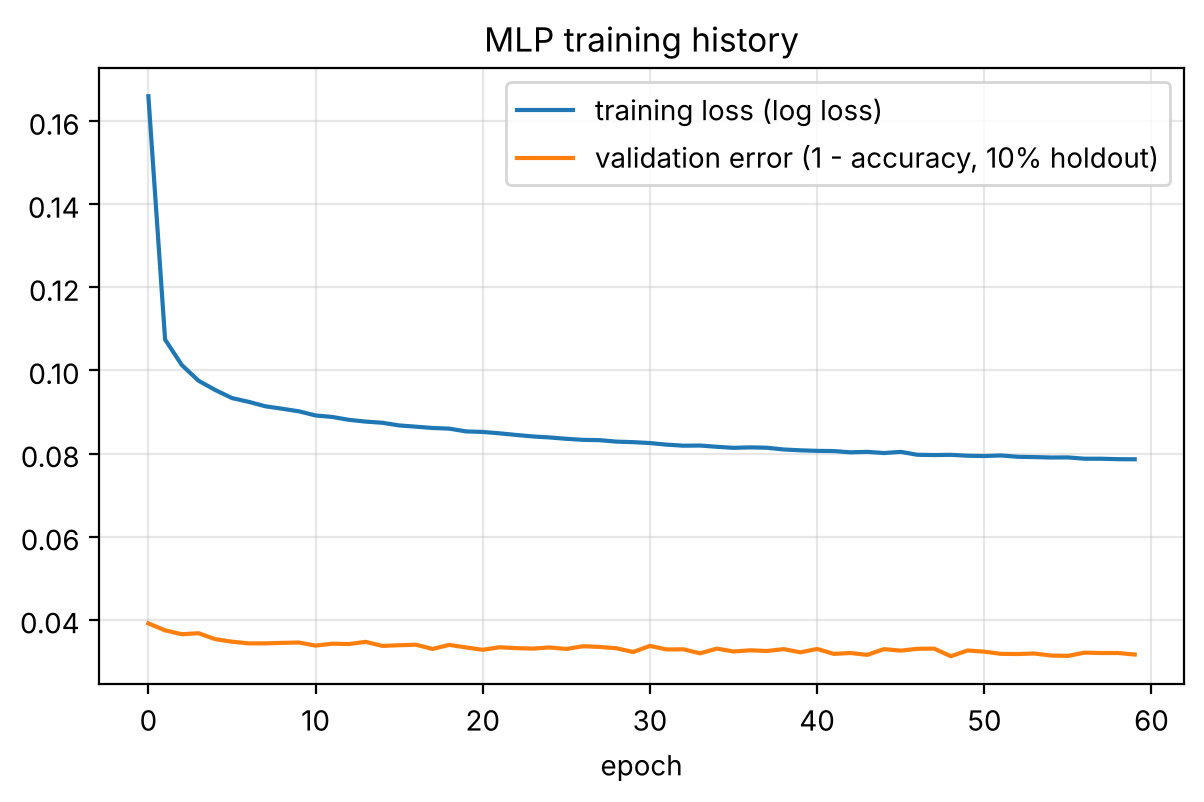

In [4]:
mlp = fitted["M7_mlp"][-1]
plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_, label="training loss (log loss)")
plt.plot(1 - pd.Series(mlp.validation_scores_), label="validation error (1 - accuracy, 10% holdout)")
plt.xlabel("epoch"); plt.legend(); plt.title("MLP training history"); plt.grid(alpha=.3)
plt.savefig("../outputs/figures/mlp_training_curve.png", dpi=120)

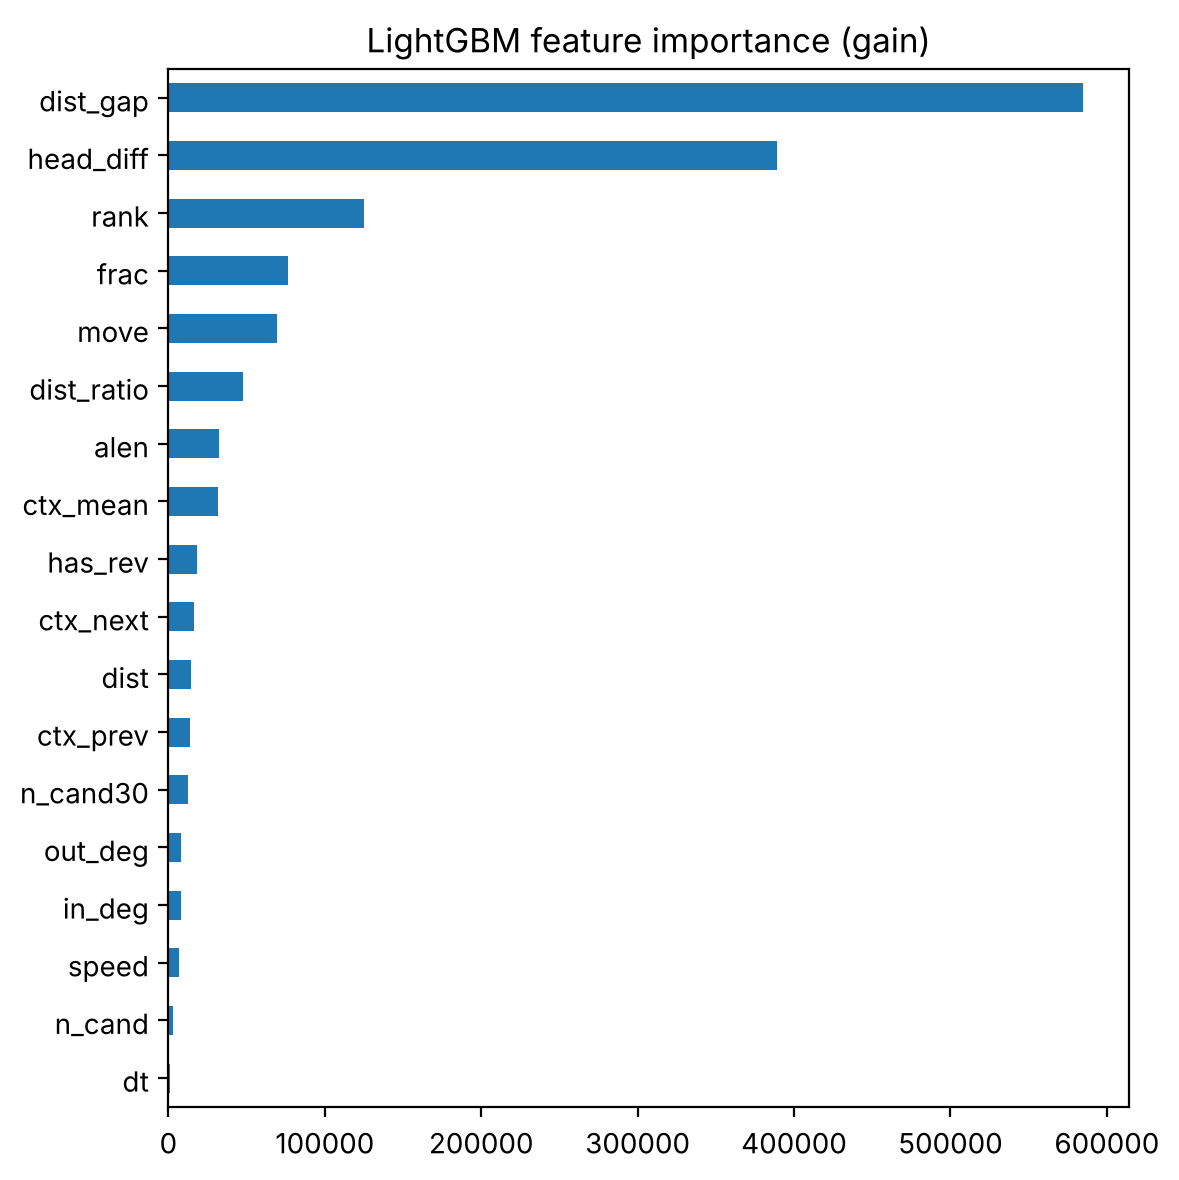

In [5]:
imp = pd.Series(fitted["M6_lightgbm"].booster_.feature_importance("gain"), index=modeling.FEATURES).sort_values()
imp.plot.barh(figsize=(6, 6), title="LightGBM feature importance (gain)"); plt.tight_layout()
plt.savefig("../outputs/figures/lgbm_importance.png", dpi=120)